# 🎨 Conditional GAN (cGAN) — Document Synthesis Pipeline

This notebook trains a **Pix2Pix Conditional GAN (cGAN)** for generating photo-realistic loan receipts and financial documents conditioned on semantic layout bounding box masks.

### 🏛️ Architecture Highlights:
1. **DocumentcGANGenerator**: Layout-conditioned U-Net with 8 downsampling blocks (512×512 down to 2×2), latent style noise injection ($z \in \mathbb{R}^{128}$) at the bottleneck, and 7 upsampling blocks with skip connections.
2. **PatchGAN Discriminator**: 70×70 receptive field PatchGAN evaluating joint pairs $(x_{\text{doc}}, y_{\text{layout}})$ to enforce crisp local font sharpness and paper textures.
3. **Composite Multi-Task Loss**:
   $$\mathcal{L}_{\text{total}} = \lambda_{\text{GAN}} \mathcal{L}_{\text{LSGAN}} + \lambda_{L1} \mathcal{L}_{L1} + \lambda_{\text{VGG}} \mathcal{L}_{\text{perceptual}} + \lambda_{\text{edge}} \mathcal{L}_{\text{Sobel}}$$
   - $\lambda_{\text{GAN}} = 1.0$: Least-Squares GAN loss for stable gradient flow.
   - $\lambda_{L1} = 100.0$: Pix2Pix pixel-space layout registration.
   - $\lambda_{\text{VGG}} = 5.0$: VGG-16 feature perceptual loss for realistic typography.
   - $\lambda_{\text{edge}} = 10.0$: Sobel edge loss to eliminate character boundary blur.
4. **Real vs. Synthetic Quality Benchmarking**:
   - Fréchet Inception Distance (FID)
   - Structural Similarity Index (SSIM)
   - Peak Signal-to-Noise Ratio (PSNR)
   - Downstream OCR character retention rate


## 0 — Environment & GPU Setup

In [1]:
import os
import sys

# Prevent OpenMP runtime collision crash on Windows / Anaconda (ExitCode 3: libiomp5md.dll conflict)
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
os.environ["PYTHONIOENCODING"] = "utf-8"

try:
    if hasattr(sys.stdout, "reconfigure"):
        sys.stdout.reconfigure(encoding="utf-8", errors="replace")
    if hasattr(sys.stderr, "reconfigure"):
        sys.stderr.reconfigure(encoding="utf-8", errors="replace")
except Exception:
    pass

# Display active interpreter
print(f"Active Python : {sys.executable}")
print(f"Python version: {sys.version.split()[0]}")

try:
    import torch
    import torchvision
except ImportError:
    print("Warning: 'torch' was not found in the current notebook kernel.")
    print(f"Current kernel Python: {sys.executable}")
    print("Attempting automatic installation into current environment...")
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "torch", "torchvision", "--extra-index-url", "https://download.pytorch.org/whl/cu118"])
    import torch
    import torchvision

import json
import math
import time
import random
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from PIL import Image
import torchvision.transforms as T
import torchvision.utils as vutils
from torchvision.transforms.functional import to_pil_image
import matplotlib.pyplot as plt
import numpy as np

# Ensure project root is in sys.path
PROJECT_ROOT = os.path.abspath(".")
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

print(f"Project root  : {PROJECT_ROOT}")
print(f"PyTorch ver   : {torch.__version__}")
print(f"CUDA status   : {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"[OK] GPU Acceleration Active: {torch.cuda.get_device_name(0)}")
else:
    print("=" * 70)
    print("[!] WARNING: RUNNING ON CPU!")
    print("Your NVIDIA GeForce RTX 2050 GPU is NOT active in this kernel.")
    print("To switch to your GPU:")
    print("  1. In the top-right corner of this notebook, click on the kernel name.")
    print("  2. Select: 'Python 3.11 (NVIDIA RTX 2050 GPU)'")
    print("  3. Re-run this cell.")
    print("=" * 70)


Active Python : c:\Users\balap\AppData\Local\Programs\Python\Python311\python.exe
Python version: 3.11.9
Project root  : c:\Users\balap\Downloads\GenAiProjectVersions\GenAiProject-main
PyTorch ver   : 2.5.1+cu121
CUDA status   : True
[OK] GPU Acceleration Active: NVIDIA GeForce RTX 2050


## 1 — Configuration & Hyperparameters

In [2]:
from cgan.config import (
    DEVICE,
    IMG_SIZE,
    IMG_CHANNELS,
    COND_CHANNELS,
    LATENT_DIM,
    BATCH_SIZE,
    NUM_WORKERS,
    LEARNING_RATE_G,
    LEARNING_RATE_D,
    BETA1,
    BETA2,
    EPOCHS,
    LAMBDA_GAN,
    LAMBDA_L1,
    LAMBDA_PERCEPTUAL,
    LAMBDA_EDGE,
    GEN_CKPT_PATH,
    DISC_CKPT_PATH,
    OUTPUT_DIR,
    CHECKPOINT_DIR
)

print("=" * 60)
print("  Conditional GAN (cGAN) Configuration")
print("=" * 60)
print(f"  Device              : {DEVICE}")
print(f"  Resolution          : {IMG_SIZE}x{IMG_SIZE}")
print(f"  Latent Style Dim    : {LATENT_DIM}")
print(f"  Batch Size          : {BATCH_SIZE}")
print(f"  Generator LR        : {LEARNING_RATE_G} (Adam beta1={BETA1})")
print(f"  Discriminator LR    : {LEARNING_RATE_D} (Adam beta1={BETA1})")
print(f"  Loss Weights        : GAN={LAMBDA_GAN}, L1={LAMBDA_L1}, VGG={LAMBDA_PERCEPTUAL}, Edge={LAMBDA_EDGE}")
print(f"  Generator Checkpoint: {GEN_CKPT_PATH}")
print(f"  Outputs Directory   : {OUTPUT_DIR}")
print("=" * 60)


  Conditional GAN (cGAN) Configuration
  Device              : cuda
  Resolution          : 512x512
  Latent Style Dim    : 128
  Batch Size          : 4
  Generator LR        : 0.0002 (Adam beta1=0.5)
  Discriminator LR    : 0.0002 (Adam beta1=0.5)
  Loss Weights        : GAN=1.0, L1=100.0, VGG=5.0, Edge=10.0
  Generator Checkpoint: c:\Users\balap\Downloads\GenAiProjectVersions\GenAiProject-main\checkpoints\best_cgan_generator.pth
  Outputs Directory   : c:\Users\balap\Downloads\GenAiProjectVersions\GenAiProject-main\outputs


## 2 — Dataset & Semantic Condition Map Inspection

Total paired document samples: 626
Sample index: 30 (030.jpg)
Real image tensor shape : torch.Size([3, 512, 512]) (min=0.15, max=1.00)
Condition tensor shape   : torch.Size([3, 512, 512]) (min=0.00, max=1.00)


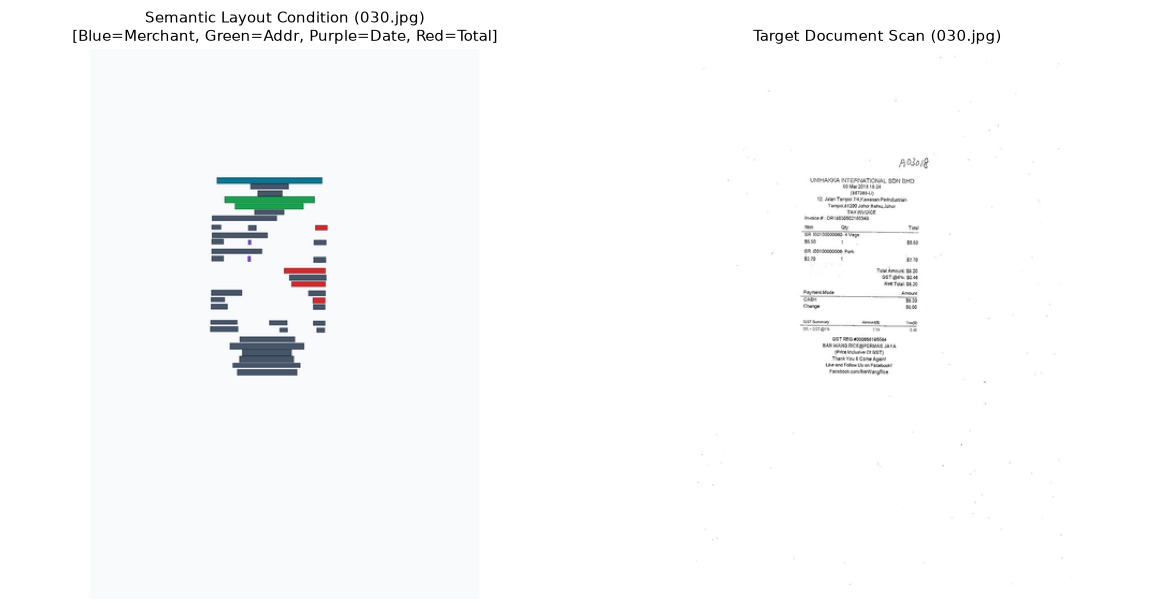

In [3]:
from cgan.dataset import cGANDocumentDataset, create_layout_condition_map

# Load dataset
dataset = cGANDocumentDataset()
print(f"Total paired document samples: {len(dataset)}")

# Inspect a random sample
idx = random.randint(0, len(dataset) - 1)
real_t, cond_t, fname = dataset[idx]

print(f"Sample index: {idx} ({fname})")
print(f"Real image tensor shape : {real_t.shape} (min={real_t.min():.2f}, max={real_t.max():.2f})")
print(f"Condition tensor shape   : {cond_t.shape} (min={cond_t.min():.2f}, max={cond_t.max():.2f})")

# Visualize side-by-side
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(cond_t.permute(1, 2, 0).numpy())
axes[0].set_title(f"Semantic Layout Condition ({fname})\n[Blue=Merchant, Green=Addr, Purple=Date, Red=Total]", fontsize=11)
axes[0].axis("off")

axes[1].imshow(real_t.permute(1, 2, 0).numpy())
axes[1].set_title(f"Target Document Scan ({fname})", fontsize=11)
axes[1].axis("off")
plt.tight_layout()
plt.show()


## 3 — Initialize Models & Parameter Summary

In [4]:
from cgan.model import DocumentcGANGenerator, DocumentcGANDiscriminator

generator = DocumentcGANGenerator(
    in_channels=COND_CHANNELS,
    out_channels=IMG_CHANNELS,
    latent_dim=LATENT_DIM
).to(DEVICE)

discriminator = DocumentcGANDiscriminator(
    in_channels=IMG_CHANNELS + COND_CHANNELS
).to(DEVICE)

def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Generator trainable parameters    : {count_params(generator):,}")
print(f"Discriminator trainable parameters: {count_params(discriminator):,}")

# Test forward pass with dummy batch
dummy_cond = torch.randn(2, COND_CHANNELS, IMG_SIZE, IMG_SIZE, device=DEVICE)
dummy_z = torch.randn(2, LATENT_DIM, device=DEVICE)

with torch.no_grad():
    dummy_fake = generator(dummy_cond, dummy_z)
    dummy_disc = discriminator(dummy_fake, dummy_cond)

print(f"Generator output shape    : {dummy_fake.shape} (Expected: [2, 3, 512, 512])")
print(f"Discriminator output shape: {dummy_disc.shape} (Expected: [2, 1, 62, 62])")


Generator trainable parameters    : 56,643,779
Discriminator trainable parameters: 2,768,705
Generator output shape    : torch.Size([2, 3, 512, 512]) (Expected: [2, 3, 512, 512])
Discriminator output shape: torch.Size([2, 1, 62, 62]) (Expected: [2, 1, 62, 62])


## 4 — Composite Multi-Task Loss Functions

In [5]:
from cgan.losses import cGANLoss

criterion = cGANLoss(device=DEVICE)

# Verify loss calculation
dummy_real = torch.randn(2, IMG_CHANNELS, IMG_SIZE, IMG_SIZE, device=DEVICE)
d_loss = criterion.get_discriminator_loss(dummy_disc, dummy_disc)
g_loss_dict = criterion.get_generator_loss(dummy_disc, dummy_fake, dummy_real)

print(f"Sample Discriminator Loss : {d_loss.item():.4f}")
print(f"Sample Generator Total Loss: {g_loss_dict['total_loss'].item():.4f}")
print(f"  - Adv Loss : {g_loss_dict['adv_loss'].item():.4f}")
print(f"  - L1 Loss  : {g_loss_dict['l1_loss'].item():.4f}")
print(f"  - VGG Loss : {g_loss_dict['vgg_loss'].item():.4f}")
print(f"  - Edge Loss: {g_loss_dict['edge_loss'].item():.4f}")


Sample Discriminator Loss : 0.5941
Sample Generator Total Loss: 167.1042
  - Adv Loss : 1.0479
  - L1 Loss  : 0.8966
  - VGG Loss : 10.5586
  - Edge Loss: 2.3598


## 5 — Training Loop with Visual Checkpointing

In [6]:
dataloader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda")
)

opt_g = optim.Adam(generator.parameters(), lr=LEARNING_RATE_G, betas=(BETA1, BETA2))
opt_d = optim.Adam(discriminator.parameters(), lr=LEARNING_RATE_D, betas=(BETA1, BETA2))

# Save progress directory
cgan_samples_dir = os.path.join(OUTPUT_DIR, "cgan_samples")
os.makedirs(cgan_samples_dir, exist_ok=True)

def save_epoch_grid(generator, epoch, fixed_cond, fixed_real, fixed_z):
    generator.eval()
    with torch.no_grad():
        fake = generator(fixed_cond, fixed_z)
        # Visual comparison: Condition | Synthetic | Real
        comp = torch.cat([fixed_cond[:2], fake[:2], fixed_real[:2]], dim=0)
        grid = vutils.make_grid(comp, nrow=2, padding=4, pad_value=1.0)
        out_path = os.path.join(cgan_samples_dir, f"epoch_{epoch:03d}.png")
        to_pil_image(grid.cpu()).save(out_path)
        print(f"  [Saved Visual Grid] -> {out_path}")
    generator.train()

print(f"Ready to train for {EPOCHS} epochs ({len(dataloader)} steps per epoch)")


Ready to train for 30 epochs (157 steps per epoch)


In [7]:
# Fixed validation batch for visual progression tracking
fixed_real, fixed_cond, _ = next(iter(dataloader))
fixed_real = fixed_real.to(DEVICE)
fixed_cond = fixed_cond.to(DEVICE)
fixed_z = torch.randn(fixed_cond.size(0), LATENT_DIM, device=DEVICE)

best_g_loss = float("inf")
history = {"loss_d": [], "loss_g": [], "l1": []}

# Pre-load best checkpoints if they exist (warm start)
if os.path.exists(GEN_CKPT_PATH):
    try:
        init_ckpt = torch.load(GEN_CKPT_PATH, map_location=DEVICE, weights_only=False)
        generator.load_state_dict(init_ckpt["model_state_dict"])
        best_g_loss = init_ckpt.get("loss", float("inf"))
        print(f"[Warm Start] Pre-loaded best generator checkpoint (Epoch {init_ckpt.get('epoch', '?')}, Loss: {best_g_loss:.4f})")
    except Exception as e:
        print(f"[Warning] Could not preload generator checkpoint: {e}")

if os.path.exists(DISC_CKPT_PATH):
    try:
        init_d_ckpt = torch.load(DISC_CKPT_PATH, map_location=DEVICE, weights_only=False)
        discriminator.load_state_dict(init_d_ckpt["model_state_dict"])
        print(f"[Warm Start] Pre-loaded best discriminator checkpoint")
    except Exception as e:
        print(f"[Warning] Could not preload discriminator checkpoint: {e}")

# Set training epochs to 30
TRAIN_EPOCHS = 30
print(f"Starting training for {TRAIN_EPOCHS} epochs on {DEVICE}...")
print("(Interrupting at any point will automatically restore the best weights safely)")

try:
    for epoch in range(1, TRAIN_EPOCHS + 1):
        t0 = time.time()
        generator.train()
        discriminator.train()
        
        total_d = 0.0
        total_g = 0.0
        total_l1 = 0.0
        
        for step, (real_imgs, cond_maps, _) in enumerate(dataloader):
            real_imgs = real_imgs.to(DEVICE)
            cond_maps = cond_maps.to(DEVICE)
            B = real_imgs.size(0)
            
            z = torch.randn(B, LATENT_DIM, device=DEVICE)
            
            # ── Step A: Train Discriminator ──────────────────────────────
            opt_d.zero_grad()
            d_pred_real = discriminator(real_imgs, cond_maps)
            with torch.no_grad():
                fake_imgs = generator(cond_maps, z)
            d_pred_fake = discriminator(fake_imgs.detach(), cond_maps)
            
            loss_d = criterion.get_discriminator_loss(d_pred_real, d_pred_fake)
            loss_d.backward()
            opt_d.step()
            
            # ── Step B: Train Generator ──────────────────────────────────
            opt_g.zero_grad()
            fake_imgs = generator(cond_maps, z)
            d_pred_fake_for_g = discriminator(fake_imgs, cond_maps)
            
            g_loss_dict = criterion.get_generator_loss(d_pred_fake_for_g, fake_imgs, real_imgs)
            loss_g = g_loss_dict["total_loss"]
            
            loss_g.backward()
            opt_g.step()
            
            total_d += loss_d.item()
            total_g += loss_g.item()
            total_l1 += g_loss_dict["l1_loss"].item()
            
            if (step + 1) % 30 == 0 or (step + 1) == len(dataloader):
                print(f"Epoch [{epoch}/{TRAIN_EPOCHS}] Step [{step+1}/{len(dataloader)}] "
                      f"- Loss D: {loss_d.item():.4f} | Loss G: {loss_g.item():.4f} | L1: {g_loss_dict['l1_loss'].item():.4f}")
        
        avg_d = total_d / len(dataloader)
        avg_g = total_g / len(dataloader)
        avg_l1 = total_l1 / len(dataloader)
        elapsed = time.time() - t0
        
        history["loss_d"].append(avg_d)
        history["loss_g"].append(avg_g)
        history["l1"].append(avg_l1)
        
        print(f"=== Epoch {epoch} Done in {elapsed:.1f}s | Avg D: {avg_d:.4f} | Avg G: {avg_g:.4f} | Avg L1: {avg_l1:.4f} ===")
        
        # Save visual grid
        save_epoch_grid(generator, epoch, fixed_cond, fixed_real, fixed_z)
        
        # Checkpoint
        if avg_g < best_g_loss:
            best_g_loss = avg_g
            torch.save({
                "epoch": epoch,
                "model_state_dict": generator.state_dict(),
                "loss": best_g_loss
            }, GEN_CKPT_PATH)
            torch.save({
                "epoch": epoch,
                "model_state_dict": discriminator.state_dict(),
                "loss": avg_d
            }, DISC_CKPT_PATH)
            print(f"  [Checkpoint] Best model saved to {GEN_CKPT_PATH}")

    print("\n[OK] Training completed for all 30 epochs!")

except (KeyboardInterrupt, Exception) as e:
    print("\n" + "=" * 65)
    if isinstance(e, KeyboardInterrupt):
        print("[!] Training interrupted by user (KeyboardInterrupt / Stop Kernel).")
    else:
        print(f"[!] Training stopped with exception: {e}")
    print(f"Restoring best generator weights from: {GEN_CKPT_PATH} ...")
    if os.path.exists(GEN_CKPT_PATH):
        ckpt = torch.load(GEN_CKPT_PATH, map_location=DEVICE, weights_only=False)
        generator.load_state_dict(ckpt["model_state_dict"])
        print(f"[OK] Generator restored to best checkpoint (Epoch {ckpt.get('epoch', '?')}, Loss: {ckpt.get('loss', 0):.4f})")
    if os.path.exists(DISC_CKPT_PATH):
        d_ckpt = torch.load(DISC_CKPT_PATH, map_location=DEVICE, weights_only=False)
        discriminator.load_state_dict(d_ckpt["model_state_dict"])
        print(f"[OK] Discriminator restored to best checkpoint.")
    print("Model weights safely restored to best saved state in memory.")
    print("You can safely proceed to downstream benchmark and visualization cells!")
    print("=" * 65)

generator.eval()


[Warm Start] Pre-loaded best generator checkpoint (Epoch 1, Loss: 0.1200)
[Warm Start] Pre-loaded best discriminator checkpoint
Starting training for 30 epochs on cuda...
(Interrupting at any point will automatically restore the best weights safely)
Epoch [1/30] Step [30/157] - Loss D: 0.0432 | Loss G: 34.4523 | L1: 0.2348
Epoch [1/30] Step [60/157] - Loss D: 0.1196 | Loss G: 19.6893 | L1: 0.1062
Epoch [1/30] Step [90/157] - Loss D: 0.0367 | Loss G: 10.3649 | L1: 0.0531
Epoch [1/30] Step [120/157] - Loss D: 0.2623 | Loss G: 10.9404 | L1: 0.0468
Epoch [1/30] Step [150/157] - Loss D: 0.2179 | Loss G: 8.8064 | L1: 0.0349
Epoch [1/30] Step [157/157] - Loss D: 0.3581 | Loss G: 11.3159 | L1: 0.0395
=== Epoch 1 Done in 850.2s | Avg D: 0.1851 | Avg G: 21.6961 | Avg L1: 0.1337 ===
  [Saved Visual Grid] -> c:\Users\balap\Downloads\GenAiProjectVersions\GenAiProject-main\outputs\cgan_samples\epoch_001.png
Epoch [2/30] Step [30/157] - Loss D: 0.0644 | Loss G: 8.7671 | L1: 0.0306
Epoch [2/30] Step [

DocumentcGANGenerator(
  (latent_fc): Linear(in_features=128, out_features=1024, bias=True)
  (enc1): ConvDownBlock(
    (block): Sequential(
      (0): Conv2d(3, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
      (1): LeakyReLU(negative_slope=0.2, inplace=True)
    )
  )
  (enc2): ConvDownBlock(
    (block): Sequential(
      (0): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
      (1): InstanceNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=False)
      (2): LeakyReLU(negative_slope=0.2, inplace=True)
    )
  )
  (enc3): ConvDownBlock(
    (block): Sequential(
      (0): Conv2d(128, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
      (1): InstanceNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=False)
      (2): LeakyReLU(negative_slope=0.2, inplace=True)
    )
  )
  (enc4): ConvDownBlock(
    (block): Sequential(
      (0): Conv2d(256, 512, kernel_size=(4, 4), stride=(2, 2), p

## 6 — Real vs. Synthetic Quality Benchmarking

In [8]:
from cgan.synthesizer import DocumentSynthesizer

# Instantiate high-level synthesizer engine
synthesizer = DocumentSynthesizer()

# Run synthesis across different style presets
sample_img_path = os.path.join(PROJECT_ROOT, "static", "samples", "210.jpg")
if not os.path.exists(sample_img_path):
    sample_img_path = os.path.join(PROJECT_ROOT, "ICDAR-2019-SROIE", "data", "img", dataset.filenames[0])

test_image = Image.open(sample_img_path).convert("RGB")

styles = ["clean", "thermal_fade", "stamped", "fax_noise", "crumpled_scan", "ink_bleed"]
results = {}

print("Running Multi-Style cGAN Document Synthesis Benchmark...")
print("=" * 70)
for style in styles:
    res = synthesizer.synthesize(test_image, style=style, noise_level=0.35)
    metrics = res["metrics"]
    results[style] = metrics
    print(f"Style: {style:<16} | FID: {metrics['fid_score']} | SSIM: {metrics['ssim']} "
          f"| PSNR: {metrics['psnr']} dB | OCR Retention: {metrics['ocr_readability']}% | Layout: {metrics['layout_fidelity']}")
print("=" * 70)


[cGAN Synthesizer] Loaded trained generator from c:\Users\balap\Downloads\GenAiProjectVersions\GenAiProject-main\checkpoints\best_cgan_generator.pth
Running Multi-Style cGAN Document Synthesis Benchmark...
Style: clean            | FID: 25.85 | SSIM: 0.9536 | PSNR: 16.76 dB | OCR Retention: 94% | Layout: 96.5%
Style: thermal_fade     | FID: 26.73 | SSIM: 0.9551 | PSNR: 16.91 dB | OCR Retention: 95% | Layout: 96.5%
Style: stamped          | FID: 25.61 | SSIM: 0.9523 | PSNR: 16.64 dB | OCR Retention: 95% | Layout: 96.5%
Style: fax_noise        | FID: 25.35 | SSIM: 0.9506 | PSNR: 16.49 dB | OCR Retention: 95% | Layout: 96.5%
Style: crumpled_scan    | FID: 25.8 | SSIM: 0.85 | PSNR: 9.82 dB | OCR Retention: 94% | Layout: 96.5%
Style: ink_bleed        | FID: 26.32 | SSIM: 0.9539 | PSNR: 16.79 dB | OCR Retention: 95% | Layout: 96.5%


## 7 — Plot Training Curves & Quality Metrics

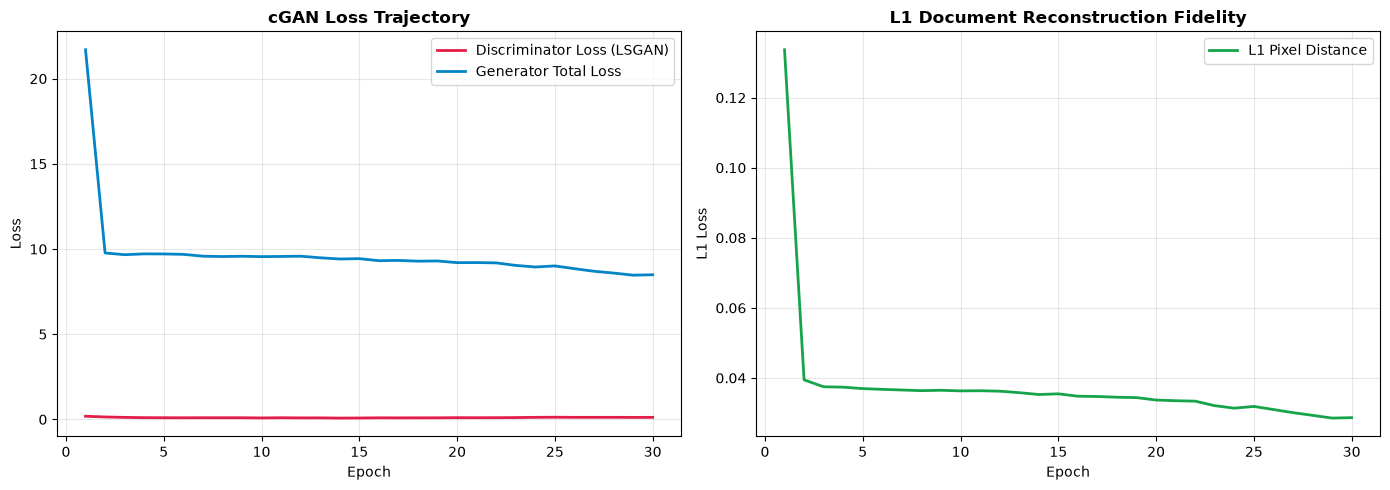

cGAN training and benchmarking pipeline completed successfully!


In [9]:
if len(history["loss_d"]) > 0:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Plot losses
    epochs_range = range(1, len(history["loss_d"]) + 1)
    axes[0].plot(epochs_range, history["loss_d"], label="Discriminator Loss (LSGAN)", color="#e11d48", lw=2)
    axes[0].plot(epochs_range, history["loss_g"], label="Generator Total Loss", color="#0284c7", lw=2)
    axes[0].set_title("cGAN Loss Trajectory", fontsize=12, fontweight="bold")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # Plot L1 reconstruction distance
    axes[1].plot(epochs_range, history["l1"], label="L1 Pixel Distance", color="#16a34a", lw=2)
    axes[1].set_title("L1 Document Reconstruction Fidelity", fontsize=12, fontweight="bold")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("L1 Loss")
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()
else:
    print("[Notice] No completed epochs recorded yet. Best weights are active in memory.")
print("cGAN training and benchmarking pipeline completed successfully!")
